In [1]:
import pandas as pd
import json
import os
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

In [2]:
BASE = 'data'

In [3]:
bills_df = pd.read_csv(os.path.join(BASE, 'medical_bills_ground_truth.csv'))
discharge_df = pd.read_csv(os.path.join(BASE, 'discharge_summaries_ground_truth.csv'))

print(f'Hospital Bills: {len(bills_df)} rows')
print(f'Discharge Summaries: {len(discharge_df)} rows')
print(f'Total Document: {len(bills_df) + len(discharge_df)}')


Hospital Bills: 500 rows
Discharge Summaries: 500 rows
Total Document: 1000


In [4]:
bills_df.head(3)

,filename,document_type,json_data
0,med_doc_bill_100001_noisy.jpg,bill,"{\n ""hospital"": {\n ""name"": ""Lilavati Hosp..."
1,med_doc_bill_100002_noisy.jpg,bill,"{\n ""hospital"": {\n ""name"": ""Manipal Hospi..."
2,med_doc_bill_100003_noisy.jpg,bill,"{\n ""hospital"": {\n ""name"": ""Lilavati Hosp..."


In [5]:
for i in bills_df.iterrows():
    print(i)
    break

(0, filename                             med_doc_bill_100001_noisy.jpg
document_type                                                 bill
json_data        {\n  "hospital": {\n    "name": "Lilavati Hosp...
Name: 0, dtype: str)


In [6]:
def parse_json(df):
    records = []
    for _, row in df.iterrows():
        data = json.loads(row['json_data'])
        records.append({
            'filename': row['filename'],
            'document_type':row['document_type'],
            'hospital': data['hospital']['name'],
            'patient': data['patient']['name'],
            'diagnosis': data['patient']['name'],
            'icd_10': data['icd_10'],
            'num_procedures': len(data['procedures']),
            'num_medications': len(data['medications']),
            'total_charges': data['financials']['total_charges'],
            'insurance_adj': data['financials']['insurance_adjustment'],
            'patient_owes': data['financials']['patient_responsibility'],
            'insurance': data['insurance']
        })

    return pd.DataFrame(records) 

bills_flat = parse_json(bills_df)
discharge_flat = parse_json(discharge_df)

bills_flat.head()





,filename,document_type,hospital,patient,diagnosis,icd_10,num_procedures,num_medications,total_charges,insurance_adj,patient_owes,insurance
0,med_doc_bill_100001_noisy.jpg,bill,Lilavati Hospital,Amit Singh,Amit Singh,E78.5,5,2,1508,1309,199,HDFC ERGO General Insurance
1,med_doc_bill_100002_noisy.jpg,bill,Manipal Hospital,Vikram Reddy,Vikram Reddy,E11.9,4,2,1301,883,418,HDFC ERGO General Insurance
2,med_doc_bill_100003_noisy.jpg,bill,Lilavati Hospital,Pooja Joshi,Pooja Joshi,I10,2,3,106,83,23,Star Health and Allied Insurance
3,med_doc_bill_100004_noisy.jpg,bill,Apollo Health City,Neha Gupta,Neha Gupta,E11.9,6,1,2096,1871,225,ICICI Lombard General Insurance
4,med_doc_bill_100005_noisy.jpg,bill,Lilavati Hospital,Rahul Verma,Rahul Verma,E11.9,4,1,1314,798,516,ICICI Lombard General Insurance


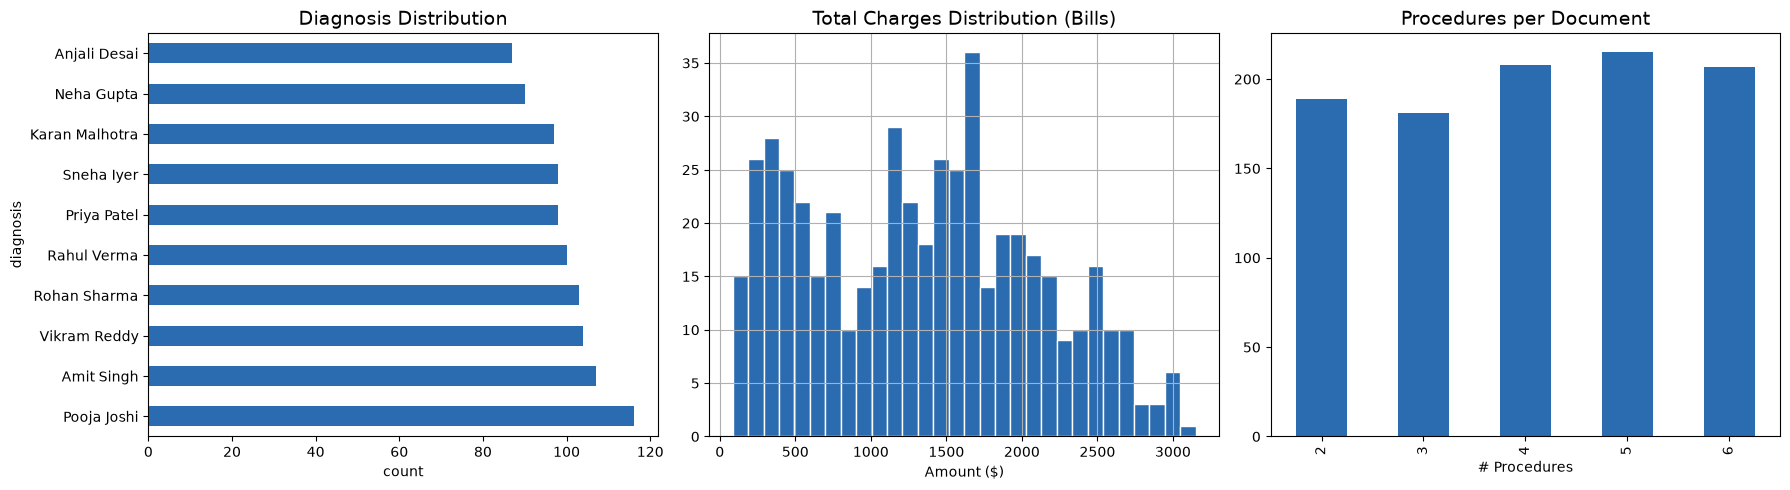

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))

#Diagnosis Distribution
all_flat = pd.concat([bills_flat, discharge_flat])
all_flat['diagnosis'].value_counts().plot.barh(ax=axes[0], color='#2B6CB0')
axes[0].set_title('Diagnosis Distribution' , fontsize=14)
axes[0].set_xlabel('count')

#Total Charges Distribution
bills_flat['total_charges'].hist(ax=axes[1], bins=30, color='#2B6CB0', edgecolor='white')
axes[1].set_title('Total Charges Distribution (Bills)', fontsize=14)
axes[1].set_xlabel('Amount ($)')

#Procedures per Documnet
all_flat['num_procedures'].value_counts().sort_index().plot.bar(ax=axes[2], color='#2B6CB0')
axes[2].set_title('Procedures per Document', fontsize=14)
axes[2].set_xlabel('# Procedures')


plt.tight_layout()
plt.show()


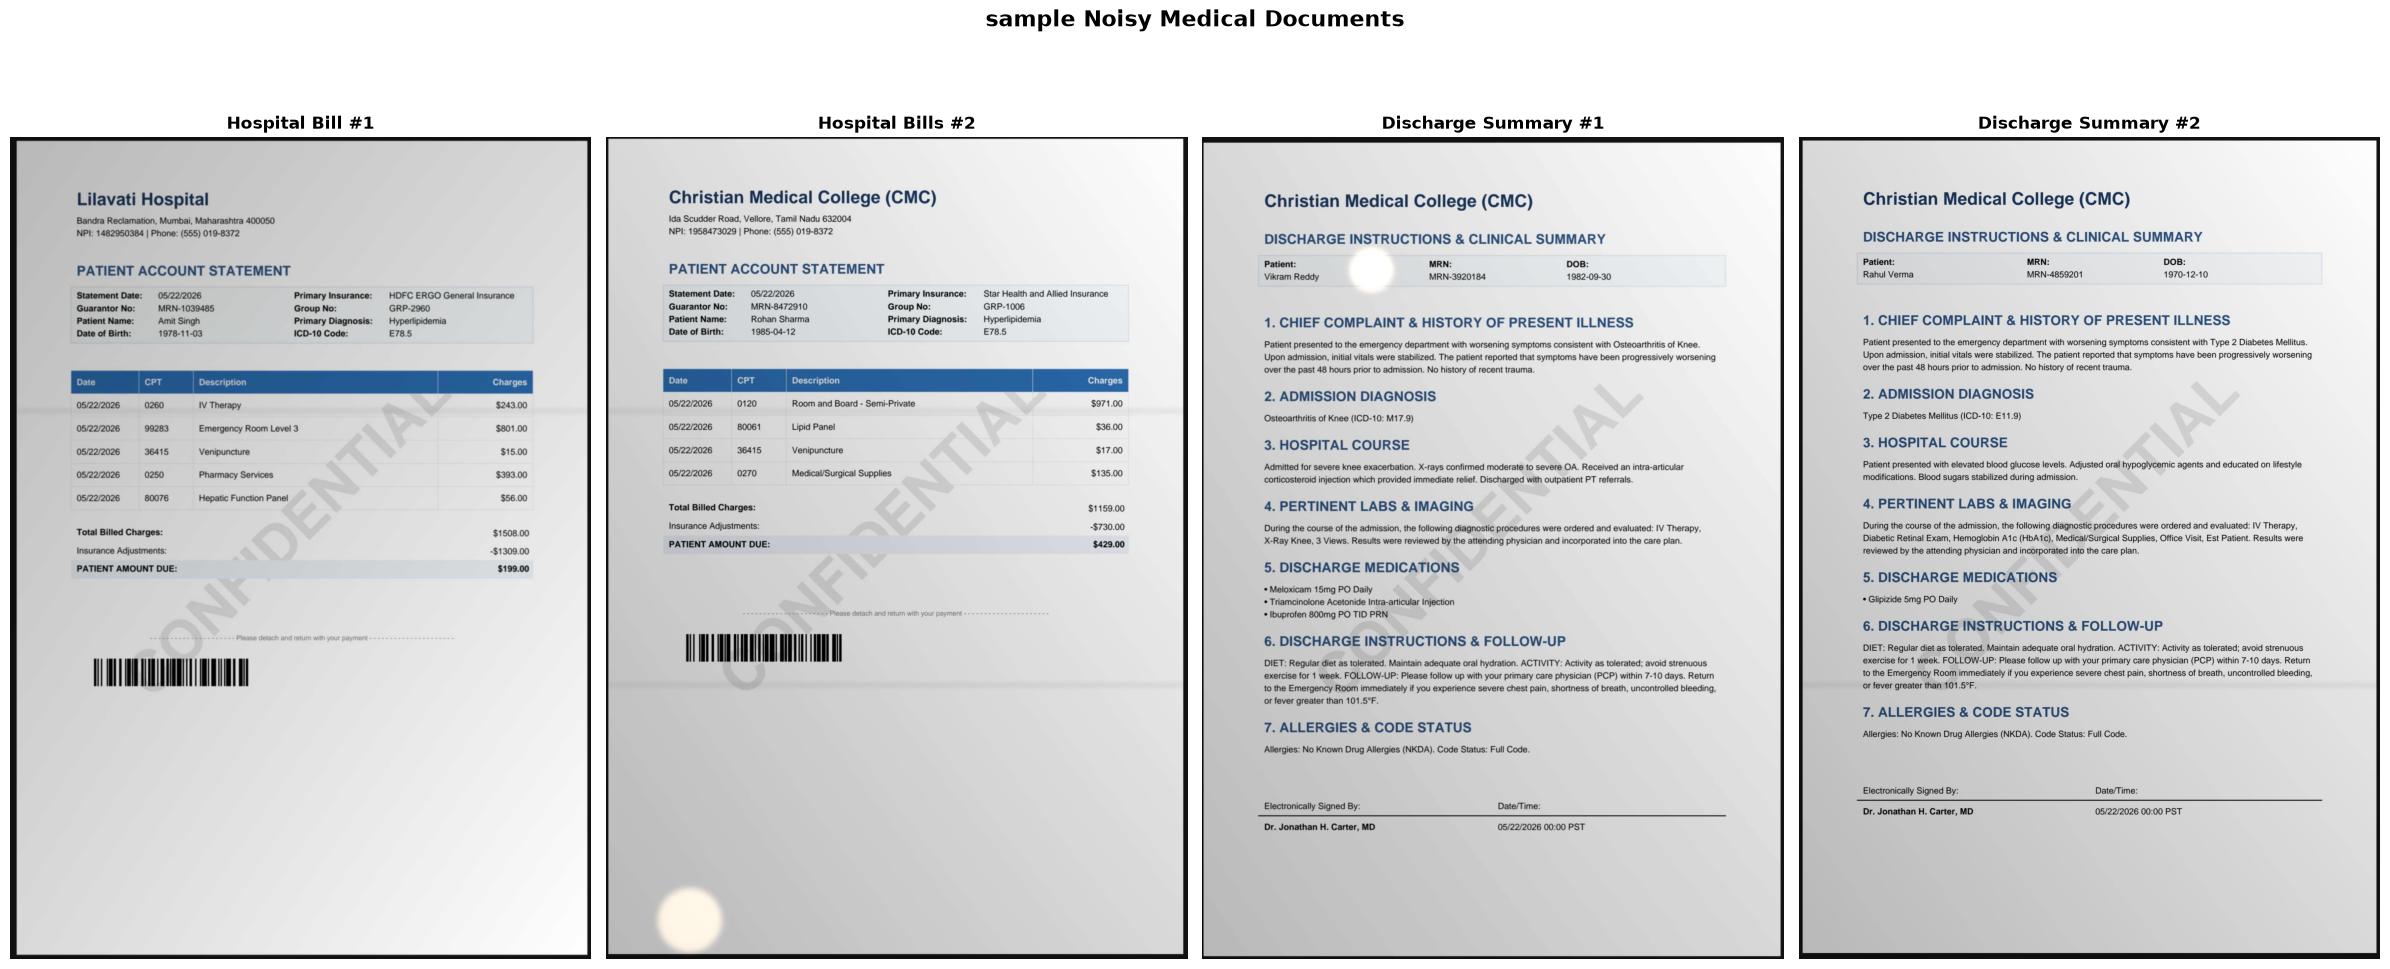

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(24, 10))

#Include the specific folder name for each sample

samples = [
    (bills_df.iloc[0], 'Hospital Bill #1' , 'bills'),
    (bills_df.iloc[5], 'Hospital Bills #2' , 'bills'),
    (discharge_df.iloc[0], 'Discharge Summary #1' , 'discharge_summaries'),
    (discharge_df.iloc[5], 'Discharge Summary #2' , 'discharge_summaries')
]

#Use a single loop with the correct subfolder path
for ax, (row, title, folder) in zip(axes, samples):
    img = Image.open(os.path.join(BASE, folder, row['filename']))
    ax.imshow(img)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.suptitle('sample Noisy Medical Documents', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()    

In [9]:
try:
    import pytesseract

    row = bills_df.iloc[0]
    data = json.loads(row['json_data'])

    #FIX: changed images to bills to match your folder structure
    img = Image.open(os.path.join(BASE, 'bills', row['filename']))

    #Run OCR
    ocr_text = pytesseract.image_to_string(img)

    #Check if key fields were captured
    patient_name = data['patient']['name']
    diagnosis = data['diagnosis']

    print(f'Ground Truth Patient: {patient_name}')
    print(f'OCR Found patient: {patient_name in ocr_text}')
    print(f'\nGround Truth Diagnosis: {diagnosis}')
    print(f'OCR Found Diagnosis: {diagnosis in ocr_text}')
    print(f'\n---First 500 char of OCR output---')

except Exception as e:
    print('pytesseract not installed. Uncomment the install lines above to enable OCR', e)    

pytesseract not installed. Uncomment the install lines above to enable OCR No module named 'pytesseract'


In [10]:
ocr_text

NameError: name 'ocr_text' is not defined

In [ ]:
row1 = discharge_df.iloc[0]
img1 = Image.open(os.path.join(BASE, 'discharge_summaries', row1['filename']))

#Run OCR
ocr_text1 = pytesseract.image_to_string(img1)
ocr_text1

'Christian Medical College (CMC)\n\nDISCHARGE INSTRUCTIONS & CLINICAL SUMMARY\n\nPatient: MRN: DOB:\nVikram Reddy MRN-3920184 1982-09-30\n\n1. CHIEF COMPLAINT & HISTORY OF PRESENT ILLNESS\n\nPatient presented to the emergency department with worsening symptoms consistent with Osteoarthritis of Knee.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.\n\n2. ADMISSION DIAGNOSIS\n\nOsteoarthritis of Knee (ICD-10: M17.9)\n\n3. HOSPITAL COURSE\n\nAdmitted for severe knee exacerbation. X-rays confirmed moderate to severe OA. Received an intra-articular\ncorticosteroid injection which provided immediate relief. Discharged with outpatient PT referrals.\n\n4. PERTINENT LABS & IMAGING\n\nDuring the course of the admission, the following diagnostic procedures were ordered and evaluated: IV Therapy,\nX-Ray Knee, 3 Views. Results were reviewed by the attending p

In [ ]:
import re

match = re.search(r'Patient:\s*MRN:.*?\n([A-Za-z ]+)\s+MRN-', ocr_text1, re.DOTALL)

if match:
    print(match.group(1))

Vikram Reddy


In [ ]:
import re

def extract_discharge_summary(text):
    """
    Extract structured information from a discharge summary OCR text.
    Input:
        text (str): OCR extracted text
    Output:
        dict: Structured discharge summary
    """

    # Hospital
    hospital = re.search(r'^(.*)', text)
    hospital = hospital.group(1).strip() if hospital else None

    # Patient Name
    patient = re.search(
        r'Patient:\s*MRN:\s*DOB:\s*\n([A-Za-z ]+)\s+MRN-',
        text,
        re.MULTILINE
    )
    patient_name = patient.group(1).strip() if patient else None

    # MRN
    mrn = re.search(r'(MRN-\d+)', text)
    mrn = mrn.group(1) if mrn else None

    # Date of Birth
    dob = re.search(r'(\d{4}-\d{2}-\d{2})', text)
    dob = dob.group(1) if dob else None

    # Chief Complaint
    chief = re.search(
        r'Patient presented.*?consistent with (.*?)\.',
        text,
        re.DOTALL
    )
    chief_complaint = chief.group(1).strip() if chief else None

    # History of Present Illness
    history = re.search(
        r'1\. CHIEF COMPLAINT.*?\n\n(.*?)\n\n2\.',
        text,
        re.DOTALL
    )
    history = history.group(1).strip() if history else None

    # Diagnosis
    diagnosis = re.search(
        r'2\. ADMISSION DIAGNOSIS\s*\n\n(.*?)\s*\(ICD-10',
        text,
        re.DOTALL
    )
    diagnosis = diagnosis.group(1).strip() if diagnosis else None

    # ICD-10
    icd = re.search(
        r'ICD-10:\s*([A-Z]\d+\.\d+)',
        text
    )
    icd10 = icd.group(1) if icd else None

    # Hospital Course
    course = re.search(
        r'3\. HOSPITAL COURSE\s*\n\n(.*?)\n\n4\.',
        text,
        re.DOTALL
    )
    hospital_course = course.group(1).strip() if course else None

    # Procedures
    procedures_match = re.search(
        r'4\. PERTINENT LABS & IMAGING\s*\n\n.*?:\s*(.*?)\.',
        text,
        re.DOTALL
    )

    if procedures_match:
        procedures = [
            p.strip()
            for p in procedures_match.group(1).split(",")
        ]
    else:
        procedures = []

    # Medications
    medications = re.findall(
        r'\*\s*(.*)',
        text
    )

    # Diet
    diet = re.search(
        r'DIET:\s*(.*?)\.',
        text
    )
    diet = diet.group(1).strip() if diet else None

    # Activity
    activity = re.search(
        r'ACTIVITY:\s*(.*?)\.',
        text
    )
    activity = activity.group(1).strip() if activity else None

    # Follow Up
    follow = re.search(
        r'FOLLOW-UP:\s*(.*?)Return',
        text,
        re.DOTALL
    )
    follow_up = follow.group(1).strip() if follow else None

    # Emergency Instructions
    emergency = re.search(
        r'Return.*?if you experience(.*?)\.',
        text,
        re.DOTALL
    )
    emergency = emergency.group(1).strip() if emergency else None

    # Allergies
    allergy = re.search(
        r'Allergies:\s*(.*?)\.',
        text
    )
    allergies = allergy.group(1).strip() if allergy else None

    # Code Status
    code = re.search(
        r'Code Status:\s*(.*?)\.',
        text
    )
    code_status = code.group(1).strip() if code else None

    # Doctor
    doctor = re.search(
        r'Electronically Signed By:.*?\n\n(.*?)\s+\d{2}/\d{2}/\d{4}',
        text,
        re.DOTALL
    )
    doctor = doctor.group(1).strip() if doctor else None

    # Discharge Date
    discharge = re.search(
        r'(\d{2}/\d{2}/\d{4})',
        text
    )
    discharge_date = discharge.group(1) if discharge else None

    return {
        "hospital": hospital,
        "patient_name": patient_name,
        "mrn": mrn,
        "dob": dob,
        "chief_complaint": chief_complaint,
        "history_of_present_illness": history,
        "diagnosis": diagnosis,
        "icd10": icd10,
        "hospital_course": hospital_course,
        "procedures": procedures,
        "medications": medications,
        "diet": diet,
        "activity": activity,
        "follow_up": follow_up,
        "emergency_instructions": emergency,
        "allergies": allergies,
        "code_status": code_status,
        "doctor": doctor,
        "discharge_date": discharge_date
    }

In [ ]:
extract_discharge_summary(ocr_text1)

{'hospital': 'Christian Medical College (CMC)',
 'patient_name': 'Vikram Reddy',
 'mrn': 'MRN-3920184',
 'dob': '1982-09-30',
 'chief_complaint': 'Osteoarthritis of Knee',
 'history_of_present_illness': 'Patient presented to the emergency department with worsening symptoms consistent with Osteoarthritis of Knee.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.',
 'diagnosis': 'Osteoarthritis of Knee',
 'icd10': 'M17.9',
 'hospital_course': 'Admitted for severe knee exacerbation. X-rays confirmed moderate to severe OA. Received an intra-articular\ncorticosteroid injection which provided immediate relief. Discharged with outpatient PT referrals.',
 'procedures': ['IV Therapy', 'X-Ray Knee', '3 Views'],
 'medications': ['Meloxicam 15mg PO Daily',
  'Triamcinolone Acetonide Intra-articular Injection',
  'Ibuprofen 800mg PO TID PRN'],
 'diet': 'Regula

In [ ]:
row1 = discharge_df.iloc[0]
img1 = Image.open(os.path.join(BASE, 'discharge_summaries', row1['filename']))

#Run OCR
ocr_text1 = pytesseract.image_to_string(img1)
ocr_text1

'Christian Medical College (CMC)\n\nDISCHARGE INSTRUCTIONS & CLINICAL SUMMARY\n\nPatient: MRN: DOB:\nVikram Reddy MRN-3920184 1982-09-30\n\n1. CHIEF COMPLAINT & HISTORY OF PRESENT ILLNESS\n\nPatient presented to the emergency department with worsening symptoms consistent with Osteoarthritis of Knee.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.\n\n2. ADMISSION DIAGNOSIS\n\nOsteoarthritis of Knee (ICD-10: M17.9)\n\n3. HOSPITAL COURSE\n\nAdmitted for severe knee exacerbation. X-rays confirmed moderate to severe OA. Received an intra-articular\ncorticosteroid injection which provided immediate relief. Discharged with outpatient PT referrals.\n\n4. PERTINENT LABS & IMAGING\n\nDuring the course of the admission, the following diagnostic procedures were ordered and evaluated: IV Therapy,\nX-Ray Knee, 3 Views. Results were reviewed by the attending p

In [ ]:
discharge_df.head()

,filename,document_type,json_data
0,med_doc_discharge_summary_200001_noisy.jpg,discharge_summary,"{\n ""hospital"": {\n ""name"": ""Christian Med..."
1,med_doc_discharge_summary_200002_noisy.jpg,discharge_summary,"{\n ""hospital"": {\n ""name"": ""Apollo Health..."
2,med_doc_discharge_summary_200003_noisy.jpg,discharge_summary,"{\n ""hospital"": {\n ""name"": ""Christian Med..."
3,med_doc_discharge_summary_200004_noisy.jpg,discharge_summary,"{\n ""hospital"": {\n ""name"": ""Lilavati Hosp..."
4,med_doc_discharge_summary_200005_noisy.jpg,discharge_summary,"{\n ""hospital"": {\n ""name"": ""Fortis Escort..."


In [ ]:
for i in discharge_df['filename']:
    print(i)

med_doc_discharge_summary_200001_noisy.jpg
med_doc_discharge_summary_200002_noisy.jpg
med_doc_discharge_summary_200003_noisy.jpg
med_doc_discharge_summary_200004_noisy.jpg
med_doc_discharge_summary_200005_noisy.jpg
med_doc_discharge_summary_200006_noisy.jpg
med_doc_discharge_summary_200007_noisy.jpg
med_doc_discharge_summary_200008_noisy.jpg
med_doc_discharge_summary_200009_noisy.jpg
med_doc_discharge_summary_200010_noisy.jpg
med_doc_discharge_summary_200011_noisy.jpg
med_doc_discharge_summary_200012_noisy.jpg
med_doc_discharge_summary_200013_noisy.jpg
med_doc_discharge_summary_200014_noisy.jpg
med_doc_discharge_summary_200015_noisy.jpg
med_doc_discharge_summary_200016_noisy.jpg
med_doc_discharge_summary_200017_noisy.jpg
med_doc_discharge_summary_200018_noisy.jpg
med_doc_discharge_summary_200019_noisy.jpg
med_doc_discharge_summary_200020_noisy.jpg
med_doc_discharge_summary_200021_noisy.jpg
med_doc_discharge_summary_200022_noisy.jpg
med_doc_discharge_summary_200023_noisy.jpg
med_doc_dis

In [ ]:
import pytesseract

patient = []
for i in discharge_df['filename']:
    img1 = Image.open(os.path.join(BASE, 'discharge_summaries', i))
    ocr_text = pytesseract.image_to_string(img1)
    patient.append(extract_discharge_summary(ocr_text))

KeyboardInterrupt: 

In [ ]:
patient[0]

{'hospital': 'Christian Medical College (CMC)',
 'patient_name': 'Vikram Reddy',
 'mrn': 'MRN-3920184',
 'dob': '1982-09-30',
 'chief_complaint': 'Osteoarthritis of Knee',
 'history_of_present_illness': 'Patient presented to the emergency department with worsening symptoms consistent with Osteoarthritis of Knee.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.',
 'diagnosis': 'Osteoarthritis of Knee',
 'icd10': 'M17.9',
 'hospital_course': 'Admitted for severe knee exacerbation. X-rays confirmed moderate to severe OA. Received an intra-articular\ncorticosteroid injection which provided immediate relief. Discharged with outpatient PT referrals.',
 'procedures': ['IV Therapy', 'X-Ray Knee', '3 Views'],
 'medications': ['Meloxicam 15mg PO Daily',
  'Triamcinolone Acetonide Intra-articular Injection',
  'Ibuprofen 800mg PO TID PRN'],
 'diet': 'Regula

In [ ]:
patient[0]['dob']

'1982-09-30'

In [ ]:
from pymongo import MongoClient

connection_string = os.getenv("MONGODB_URI")

client = MongoClient(connection_string)

# Test Connection
client.admin.command("ping")

print("Connected Successfully!")

Connected Successfully!


In [ ]:
from pymongo import MongoClient

client = MongoClient(connection_string)

print(client.list_database_names())

['HospitalDB', 'sample_mflix', 'admin', 'local']


In [ ]:
from pymongo import MongoClient

client = MongoClient(connection_string)

# Database
db = client["HospitalDB"]

# Collection
collection = db["patients"]

# Insert first document
collection.insert_one(
{'hospital': 'Christian Medical College (CMC)',
 'patient_name': 'Vikram Reddy',
 'mrn': 'MRN-3920184',
 'dob': '1982-09-30',
 'chief_complaint': 'Osteoarthritis of Knee',
 'history_of_present_illness': 'Patient presented to the emergency department with worsening symptoms consistent with Osteoarthritis of Knee.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.',
 'diagnosis': 'Osteoarthritis of Knee',
 'icd10': 'M17.9',
 'hospital_course': 'Admitted for severe knee exacerbation. X-rays confirmed moderate to severe OA. Received an intra-articular\ncorticosteroid injection which provided immediate relief. Discharged with outpatient PT referrals.',
 'procedures': ['IV Therapy', 'X-Ray Knee', '3 Views'],
 'medications': ['Meloxicam 15mg PO Daily',
  'Triamcinolone Acetonide Intra-articular Injection',
  'Ibuprofen 800mg PO TID PRN'],
 'diet': 'Regular diet as tolerated',
 'activity': None,
 'follow_up': 'Please follow up with your primary care physician (PCP) within 7-10 days.',
 'emergency_instructions': 'severe chest pain, shortness of breath, uncontrolled bleeding,\nor fever greater than 101',
 'allergies': 'No Known Drug Allergies (NKDA)',
 'code_status': 'Full Code',
 'doctor': 'Dr. Jonathan H. Carter, MD',
 'discharge_date': '05/22/2026'}    
)

print("Database Created Successfully")

NameError: name 'connection_string' is not defined

In [ ]:
print(client.list_database_names())

['HospitalDB', 'sample_mflix', 'admin', 'local']


In [ ]:
patient[1:]

[{'hospital': 'Apollo Health City',
  'patient_name': 'Karan Malhotra',
  'mrn': 'MRN-3019284',
  'dob': '1992-07-15',
  'chief_complaint': 'Type 2 Diabetes Mellitus',
  'history_of_present_illness': 'Patient presented to the emergency department with worsening symptoms consistent with Type 2 Diabetes Mellitus.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.',
  'diagnosis': 'Type 2 Diabetes Mellitus',
  'icd10': 'E11.9',
  'hospital_course': 'Patient presented with elevated blood glucose levels. Adjusted oral hypoglycemic agents and educated on lifestyle\nmodifications. Blood sugars stabilized during admission.',
  'procedures': ['Pharmacy\nServices',
   'Emergency Room Level 3',
   'IV Therapy',
   'Office Visit',
   'Est Patient',
   'Diabetic Retinal Exam',
   'Comprehensive\nMetabolic Panel (CMP)'],
  'medications': ['Sitagliptin 100mg PO D

In [ ]:
result = collection.insert_many(patient[1:])
print("Inserted IDs:")
print(result.inserted_ids)

Inserted IDs:
[ObjectId('6a6391cfe1c5709dc413ae0f'), ObjectId('6a6391cfe1c5709dc413ae10'), ObjectId('6a6391cfe1c5709dc413ae11'), ObjectId('6a6391cfe1c5709dc413ae12'), ObjectId('6a6391cfe1c5709dc413ae13'), ObjectId('6a6391cfe1c5709dc413ae14'), ObjectId('6a6391cfe1c5709dc413ae15'), ObjectId('6a6391cfe1c5709dc413ae16'), ObjectId('6a6391cfe1c5709dc413ae17'), ObjectId('6a6391cfe1c5709dc413ae18'), ObjectId('6a6391cfe1c5709dc413ae19'), ObjectId('6a6391cfe1c5709dc413ae1a'), ObjectId('6a6391cfe1c5709dc413ae1b'), ObjectId('6a6391cfe1c5709dc413ae1c'), ObjectId('6a6391cfe1c5709dc413ae1d'), ObjectId('6a6391cfe1c5709dc413ae1e'), ObjectId('6a6391cfe1c5709dc413ae1f'), ObjectId('6a6391cfe1c5709dc413ae20'), ObjectId('6a6391cfe1c5709dc413ae21'), ObjectId('6a6391cfe1c5709dc413ae22'), ObjectId('6a6391cfe1c5709dc413ae23'), ObjectId('6a6391cfe1c5709dc413ae24'), ObjectId('6a6391cfe1c5709dc413ae25'), ObjectId('6a6391cfe1c5709dc413ae26'), ObjectId('6a6391cfe1c5709dc413ae27'), ObjectId('6a6391cfe1c5709dc413ae28'

In [ ]:
patient[1]

{'hospital': 'Apollo Health City',
 'patient_name': 'Karan Malhotra',
 'mrn': 'MRN-3019284',
 'dob': '1992-07-15',
 'chief_complaint': 'Type 2 Diabetes Mellitus',
 'history_of_present_illness': 'Patient presented to the emergency department with worsening symptoms consistent with Type 2 Diabetes Mellitus.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.',
 'diagnosis': 'Type 2 Diabetes Mellitus',
 'icd10': 'E11.9',
 'hospital_course': 'Patient presented with elevated blood glucose levels. Adjusted oral hypoglycemic agents and educated on lifestyle\nmodifications. Blood sugars stabilized during admission.',
 'procedures': ['Pharmacy\nServices',
  'Emergency Room Level 3',
  'IV Therapy',
  'Office Visit',
  'Est Patient',
  'Diabetic Retinal Exam',
  'Comprehensive\nMetabolic Panel (CMP)'],
 'medications': ['Sitagliptin 100mg PO Daily', 'Metformin

patient = {
    "patient_name": "Vikram Reddy",
    "age": 42,
    "diagnosis": "Osteoarthritis",
    "doctor": "Dr. Jonathan Carter"
}

result = collection.insert_one(patient)

print("Inserted ID:", result.inserted_id)

In [ ]:
patient = {'hospital': 'Apollo Health City',
 'patient_name': 'Karan Malhotra',
 'mrn': 'MRN-3019284',
 'dob': '1992-07-15',
 'chief_complaint': 'Type 2 Diabetes Mellitus',
 'history_of_present_illness': 'Patient presented to the emergency department with worsening symptoms consistent with Type 2 Diabetes Mellitus.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.',
 'diagnosis': 'Type 2 Diabetes Mellitus',
 'icd10': 'E11.9',
 'hospital_course': 'Patient presented with elevated blood glucose levels. Adjusted oral hypoglycemic agents and educated on lifestyle\nmodifications. Blood sugars stabilized during admission.',
 'procedures': ['Pharmacy\nServices',
  'Emergency Room Level 3',
  'IV Therapy',
  'Office Visit',
  'Est Patient',
  'Diabetic Retinal Exam',
  'Comprehensive\nMetabolic Panel (CMP)'],
 'medications': ['Sitagliptin 100mg PO Daily', 'Metformin 500mg PO BID'],
 'diet': 'Regular diet as tolerated',
 'activity': None,
 'follow_up': 'Please follow up with your primary care physician (PCP) within 7-10 days.',
 'emergency_instructions': 'severe chest pain, shortness of breath, uncontrolled bleeding,\nor fever greater than 101',
 'allergies': 'No Known Drug Allergies (NKDA)',
 'code_status': 'Full Code',
 'doctor': 'Dr. Jonathan H. Carter, MD',
 'discharge_date': '05/22/2026',
}

result = collection.insert_one(patient)

print("Inserted ID:", result.inserted_id)

Inserted ID: 6a6394a4e1c5709dc413b002


In [ ]:
patient = collection.find_one(
    {'patient_name': 'Karan Malhotra'}
)

print(patient)

{'_id': ObjectId('6a6391cfe1c5709dc413ae10'), 'hospital': 'Christian Medical College (CMC)', 'patient_name': 'Karan Malhotra', 'mrn': 'MRN-3019284', 'dob': '1992-07-15', 'chief_complaint': 'Osteoarthritis of Knee', 'history_of_present_illness': 'Patient presented to the emergency department with worsening symptoms consistent with Osteoarthritis of Knee.\nUpon admission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening\nover the past 48 hours prior to admission. No history of recent trauma.', 'diagnosis': None, 'icd10': 'M17.9', 'hospital_course': 'Admitted for severe knee exacerbation. X-rays confirmed moderate to severe OA. Received an intra-articular\ncorticosteroid injection which provided immediate relief. Discharged with outpatient PT referrals.', 'procedures': ['Physical\nTherapy Evaluation', 'Therapeutic Exercise', 'Emergency Room Level 3'], 'medications': ['Meloxicam 15mg PO Daily', 'Ibuprofen 800mg PO TID PRN'], 'diet': 'Regu

In [ ]:
patient = collection.update_one(
    {'patient_name': 'Karan Malhotra'},
    {
        "$set": {
            "patient_name": "Dr. Karan Malhotra"
        }
    }

)

print(patient)

UpdateResult({'n': 1, 'electionId': ObjectId('7fffffff00000000000001a1'), 'opTime': {'ts': Timestamp(1784913149, 8), 't': 417}, 'nModified': 1, 'ok': 1.0, '$clusterTime': {'clusterTime': Timestamp(1784913149, 8), 'signature': {'hash': b'\x88\xbc\x14B\xa4\x02\xd4\x9fq^\x89c\xb1\xca\x8a\x19Ne\x02\x96', 'keyId': 7610923730616713217}}, 'operationTime': Timestamp(1784913149, 8), 'updatedExisting': True}, acknowledged=True)


In [ ]:
collection.delete_one(
    {"patient_name": "Dr. Karan Malhotra"}
)

DeleteResult({'n': 1, 'electionId': ObjectId('7fffffff00000000000001a1'), 'opTime': {'ts': Timestamp(1784913431, 1), 't': 417}, 'ok': 1.0, '$clusterTime': {'clusterTime': Timestamp(1784913431, 1), 'signature': {'hash': b'p\xb0~%\xb1w\xba\x8a\x04U\xa4`\xd1w\x18f\x11j\xa9{', 'keyId': 7610923730616713217}}, 'operationTime': Timestamp(1784913431, 1)}, acknowledged=True)

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1892.19it/s]


In [ ]:
embedding = model.encode("Hello World")

print(len(embedding))
print(type(embedding))

384
<class 'numpy.ndarray'>


In [ ]:
embedding

array([-3.44772041e-02,  3.10232397e-02,  6.73496863e-03,  2.61089690e-02,
       -3.93619612e-02, -1.60302460e-01,  6.69239312e-02, -6.44147955e-03,
       -4.74505574e-02,  1.47589119e-02,  7.08753690e-02,  5.55275641e-02,
        1.91933755e-02, -2.62513272e-02, -1.01095000e-02, -2.69405413e-02,
        2.23074704e-02, -2.22266559e-02, -1.49692699e-01, -1.74930841e-02,
        7.67624797e-03,  5.43522798e-02,  3.25447368e-03,  3.17259766e-02,
       -8.46213549e-02, -2.94059906e-02,  5.15956245e-02,  4.81240302e-02,
       -3.31479218e-03, -5.82792051e-02,  4.19693030e-02,  2.22106855e-02,
        1.28188848e-01, -2.23389659e-02, -1.16563011e-02,  6.29283339e-02,
       -3.28762829e-02, -9.12260562e-02, -3.11753899e-02,  5.26995622e-02,
        4.70348559e-02, -8.42030272e-02, -3.00562084e-02, -2.07447819e-02,
        9.51781124e-03, -3.72180226e-03,  7.34334765e-03,  3.93243358e-02,
        9.32740942e-02, -3.78861465e-03, -5.27421273e-02, -5.80582172e-02,
       -6.86439546e-03,  

In [ ]:
from pymongo import MongoClient

client = MongoClient(connection_string)

db = client["HospitalDB"]

collection = db["patients"]

In [ ]:
from dotenv import load_dotenv
load_dotenv()

from pinecone import Pinecone, ServerlessSpec

pc = Pinecone(api_key=os.getenv("PINECONE_API_KEY"))

In [ ]:
# pc.create_index(
#     name="medical-rag",
#     dimension=384,
#     metric="cosine",
#     spec=ServerlessSpec(
#         cloud="aws",
#         region="us-east-1"
#     )
# )

In [ ]:
index = pc.Index("medical-rag")

In [ ]:
def create_search_text(doc):
    parts = [
        f"Hospital: {doc.get('hospital', '')}",
        f"Patient: {doc.get('patient_name', '')}",
        f"Diagnosis: {doc.get('diagnosis', '')}",
        f"Chief Complaint: {doc.get('chief_complaint', '')}",
        f"History: {doc.get('history_of_present_illness', '')}",
        f"Hospital Course: {doc.get('hospital_course', '')}",
        f"Procedures: {', '.join(doc.get('procedures', []))}",
        f"Medications: {', '.join(doc.get('medications', []))}",
        f"Follow Up: {doc.get('follow_up', '')}",
        f"Allergies: {doc.get('allergies', '')}"
    ]

    return "\n".join(parts)

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")

vectors = []

for doc in collection.find({}):

    doc_id = str(doc["_id"])
    search_text = create_search_text(doc)
    embedding = model.encode(search_text).tolist()

    metadata = {
        "text": search_text,
        "patient_name":doc.get("patient_name", ""),
        "hospital":doc.get("hospital", "")
    }

    vectors.append(
        (
            doc_id,
            embedding,
            metadata
        )
    )

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2074.39it/s]


In [ ]:
# for doc in collection.find():
#     print(doc)

In [ ]:
# vectors[:2]
# for i in vectors:
#     if i[2]['patient_name'] is None:
#         i[2]['patient_name'] = "sample"

for i in vectors:
    if i[2]['patient_name'] is None:
        print(i)
        
        

In [ ]:
batch_size = 20

for i in range(100, len(vectors), batch_size):
    index.upsert(vectors=vectors[i:i + batch_size])

print("All documnent uploaded to pinecone")

All documnent uploaded to pinecone


In [ ]:
def retrival(query,model,pinecone):
    query_embedding = model.encode(query).tolist()
    result = pinecone.query(vector=query_embedding, top_k=5, include_metadata = True)
    # result = [i for i in result.matches[i].metadata]
    metadata_list = []

    for match in result.matches:
        metadata_list.append(match.metadata)
    return metadata_list    




In [ ]:
# result.matches[0].metadata

NameError: name 'result' is not defined

In [ ]:
data = retrival("Acute Bronchitis",model,index)
print(data)

[{'hospital': 'Manipal Hospital', 'patient_name': 'Pooja Joshi', 'text': 'Hospital: Manipal Hospital\nPatient: Pooja Joshi\nDiagnosis: Acute Bronchitis\nChief Complaint: Acute Bronchitis\nHistory: Patient presented to the emergency department with worsening symptoms consistent with Acute Bronchitis. Upon\nadmission, initial vitals were stabilized. The patient reported that symptoms have been progressively worsening over\nthe past 48 hours prior to admission. No history of recent trauma.\nHospital Course: Patient presented with persistent cough and shortness of breath. Chest X-Ray confirmed no pneumonia. Treated with\nbronchodilators and a short course of oral steroids. Symptoms improved significantly.\nProcedures: Emergency\nRoom Level 3, Spirometry, Complete Blood Count (CBC), Medical/Surgical Supplies, Chest X-Ray, 1 View\nMedications: \nFollow Up: Please follow up with your primary care physician (PCP) within 7-10 days.\nAllergies: No Known Drug Allergies (NKDA)'}, {'hospital': 'Chr

In [ ]:
from google import genai

client = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))

In [ ]:
def ask_gemini(prompt):
    response = client.models.generate_content(
        model="gemini-3.5-flash",
        contents=prompt
    )

    return response.text

In [ ]:
answer = ask_gemini("What is diabetes?")
print(answer)

**Diabetes** (scientifically known as *Diabetes Mellitus*) is a chronic, long-term health condition that affects how your body turns food into energy. 

To understand diabetes, it helps to understand how the body processes sugar (glucose).

### The "Key and Lock" Analogy
When you eat, your body breaks food down into a sugar called **glucose**, which enters your bloodstream. Your cells need this glucose for energy. 

However, glucose cannot enter your cells on its own. It needs a hormone called **insulin** (which is made by the pancreas). 
* Think of **glucose** as a traveler.
* Think of your **cells** as locked houses.
* Think of **insulin** as the **key** that unlocks the doors to let the glucose inside.

In people with diabetes, the body either **doesn't make enough insulin** or **cannot use the insulin it makes** effectively. Without insulin "keys," glucose builds up in the bloodstream, leading to high blood sugar. Over time, this can cause serious health problems.

---

### The Mai

In [ ]:
def query_building(embedding_model,query,pinecone):

    retrival_result = retrival(query,embedding_model,pinecone)

    prompt = f"""
You are an expert medical AI assistant.

You have been provided with the top 5 retrieved medical document chunks from a Retrieval-Augmented Generation (RAG) system.

Instructions:
1. Carefully analyze all retrieved document chunks.
2. Identify each unique patient present in the retrieved context.
3. For EACH patient, create a separate summary.
4. Do NOT merge information from different patients.
5. Use ONLY the information provided in the retrieved context.
6. If some information is missing for a patient, write "Not Available" for that field instead of making assumptions.
7. Do not generate or infer information that is not explicitly present in the context.
8. If none of the retrieved documents contain information relevant to the user's question, respond:
   "The requested information is not available in the retrieved documents."

Retrieved Context:
{retrival_result}

User Question:
{query}

Return the answer in the following format:

Patient 1
-----------
Name:
Hospital:
Diagnosis:
Chief Complaint:
Hospital Course:
Procedures:
Medications:
Follow-up:
Summary:

Patient 2
-----------
Name:
Hospital:
Diagnosis:
Chief Complaint:
Hospital Course:
Procedures:
Medications:
Follow-up:
Summary:

Patient 3
-----------
...

Continue this format for every unique patient found in the retrieved context.
"""

    return prompt



In [ ]:
def call_llm(query):
    answer = ask_gemini(query)

    return answer

In [ ]:
query = "Acute Bronchitis"
query_result = query_building(model,query, index)

In [ ]:
llm_result = call_llm(query_result)


In [ ]:
print(llm_result)

Patient 1
-----------
Name: Pooja Joshi
Hospital: Manipal Hospital
Diagnosis: Acute Bronchitis
Chief Complaint: Acute Bronchitis
Hospital Course: Patient presented with persistent cough and shortness of breath. Chest X-Ray confirmed no pneumonia. Treated with bronchodilators and a short course of oral steroids. Symptoms improved significantly.
Procedures: Emergency Room Level 3, Spirometry, Complete Blood Count (CBC), Medical/Surgical Supplies, Chest X-Ray, 1 View
Medications: Not Available
Follow-up: Please follow up with your primary care physician (PCP) within 7-10 days.
Summary: Pooja Joshi presented to the emergency department at Manipal Hospital with progressive symptoms of acute bronchitis. A chest X-ray ruled out pneumonia, and she was successfully treated with bronchodilators and a short course of oral steroids, leading to significant symptom improvement.

Patient 2
-----------
Name: Amit Singh
Hospital: Christian Medical College (CMC)
Diagnosis: Acute Bronchitis
Chief Complai